# Line profiles -- Gaussian (Doppler-only) and full Voigt

Goal: build intuition for how N and b shape an absorption line
(Gaussian/Doppler-only limit), then add the Lorentzian/damping term to
get the full Voigt profile via `scipy.special.wofz`, and check it
against the Gaussian limit and against the expected damping-wing
behaviour for a saturated line.

See [00_reference_civ_line.ipynb](00_reference_civ_line.ipynb) for
what the test line used below is grounded in.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from spectral_diag.data_classes import Line
from spectral_diag.line_profiles import optical_depth_gaussian, optical_depth, voigt

# a simple test line (values close to a strong UV metal transition, CIV)
line = Line(species="Test", wave_rest=1550.0, f=0.1, gamma=2.65e8)
z = 0.0
# wide enough to see the Voigt damping wings later in this notebook
wave = np.linspace(1540, 1560, 4000)

## Reality check -- what does this line actually look like?

Our `Line(wave_rest=1550.0, f=0.1, gamma=2.65e8)` is a stand-in for a
real strong UV metal transition, modeled after the CIV doublet. See
[00_reference_civ_line.ipynb](00_reference_civ_line.ipynb) for the
real atomic data it's grounded in and what it looks like observed in
a real quasar spectrum -- kept there once instead of duplicated here.

## Varying N at fixed b

Expect: higher N -> deeper line core. Watch for the point where the
core stops getting deeper and only the wings keep growing -- that is
the onset of saturation, which is why the curve of growth is not a
straight line.

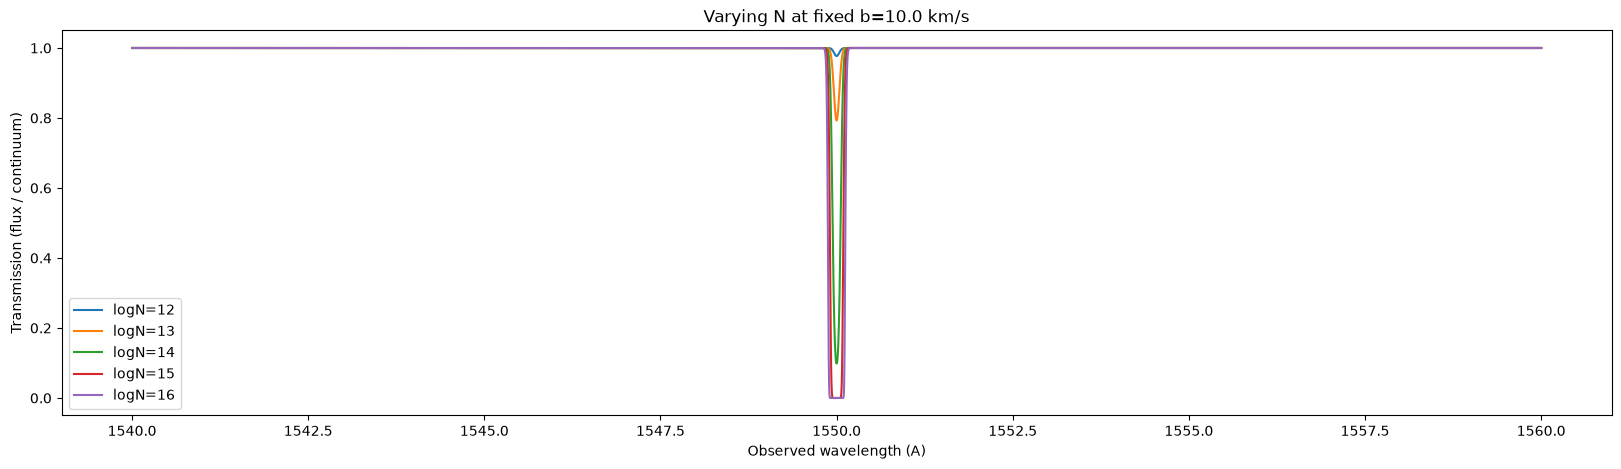

In [2]:
fig = plt.figure(figsize=(20,5))

b_fixed = 10.0  # km/s
for logN in [12, 13, 14, 15, 16]:
    tau = optical_depth_gaussian(wave, line, logN=logN, b=b_fixed, z=z)
    plt.plot(wave, np.exp(-tau), label=f"logN={logN}")
plt.xlabel("Observed wavelength (A)")
plt.ylabel("Transmission (flux / continuum)")
plt.title(f"Varying N at fixed b={b_fixed} km/s")
plt.legend()
plt.show()
plt.close(fig)

## Varying b at fixed N

Expect: higher b -> broader, shallower line, since the same amount
of gas (N) is spread over a wider velocity range.

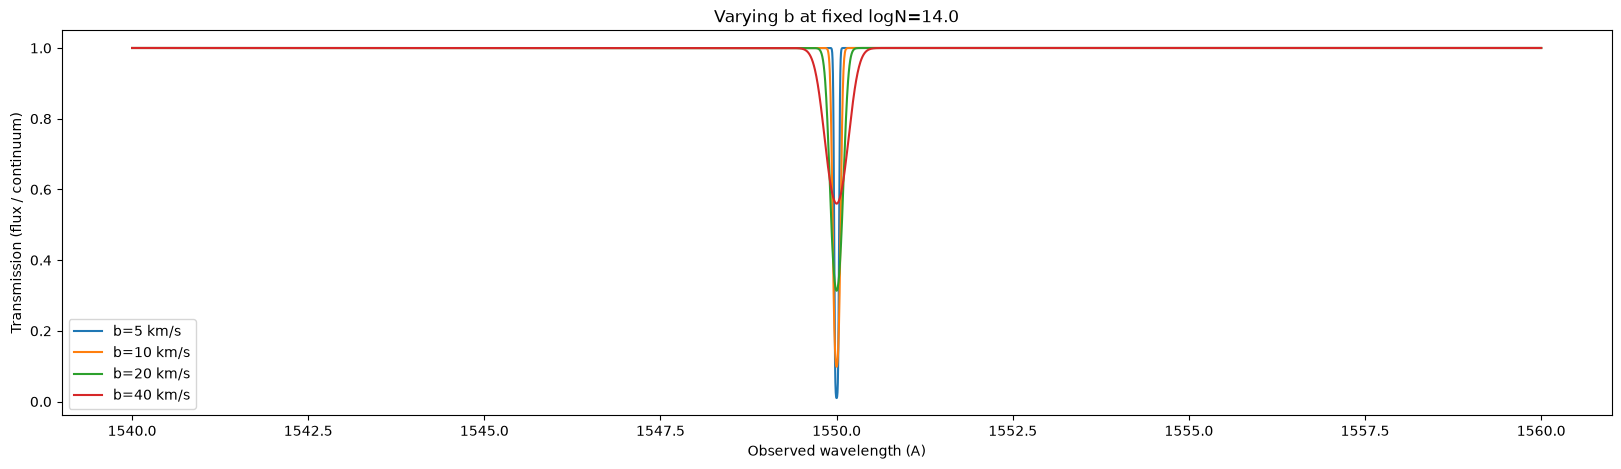

In [3]:
fig = plt.figure(figsize=(20,5))

logN_fixed = 14.0
for b in [5, 10, 20, 40]:
    tau = optical_depth_gaussian(wave, line, logN=logN_fixed, b=b, z=z)
    plt.plot(wave, np.exp(-tau), label=f"b={b} km/s")
plt.xlabel("Observed wavelength (A)")
plt.ylabel("Transmission (flux / continuum)")
plt.title(f"Varying b at fixed logN={logN_fixed}")
plt.legend()
plt.show()
plt.close(fig)

## Full Voigt profile

Add the Lorentzian (damping, Gamma) term via `scipy.special.wofz` to
get the full Voigt profile: `line_profiles.optical_depth`. Two checks:
it must reduce to the Gaussian-only result as damping -> 0, and it
must show real absorption in the wings of a saturated line where the
Gaussian-only version has already dropped to ~0.

## Test 1 -- sanity check: Voigt with ~zero damping reduces to the Gaussian

If `gamma` is negligibly small, the Voigt profile *must* reduce to the
pure-Doppler Gaussian result exactly (this is the a -> 0 limit
discussed in the notes: Re[wofz(x+i*0)] = exp(-x**2)).

In [4]:
line_nodamp = Line(species="Test", wave_rest=1550.0, f=0.1, gamma=1e-6)

tau_gaussian = optical_depth_gaussian(wave, line, logN=14, b=10, z=z)
tau_voigt_nodamp = optical_depth(wave, line_nodamp, logN=14, b=10, z=z)

max_diff = np.max(np.abs(tau_gaussian - tau_voigt_nodamp))
print(f"max |tau_gaussian - tau_voigt(gamma~0)| = {max_diff:.3e}")
assert max_diff < 1e-10, "Voigt should match Gaussian to machine precision as a -> 0"
print("PASS: Voigt profile reduces to the Gaussian limit as expected.")

max |tau_gaussian - tau_voigt(gamma~0)| = 4.337e-19
PASS: Voigt profile reduces to the Gaussian limit as expected.


## Test 2 -- damping wings appear for a saturated line

For a heavily saturated line (large N), the Gaussian-only core goes
black and *stays* black -- no more wings grow. The full Voigt profile
should show visibly larger optical depth far from line center, where
the Gaussian has already died off to ~0.

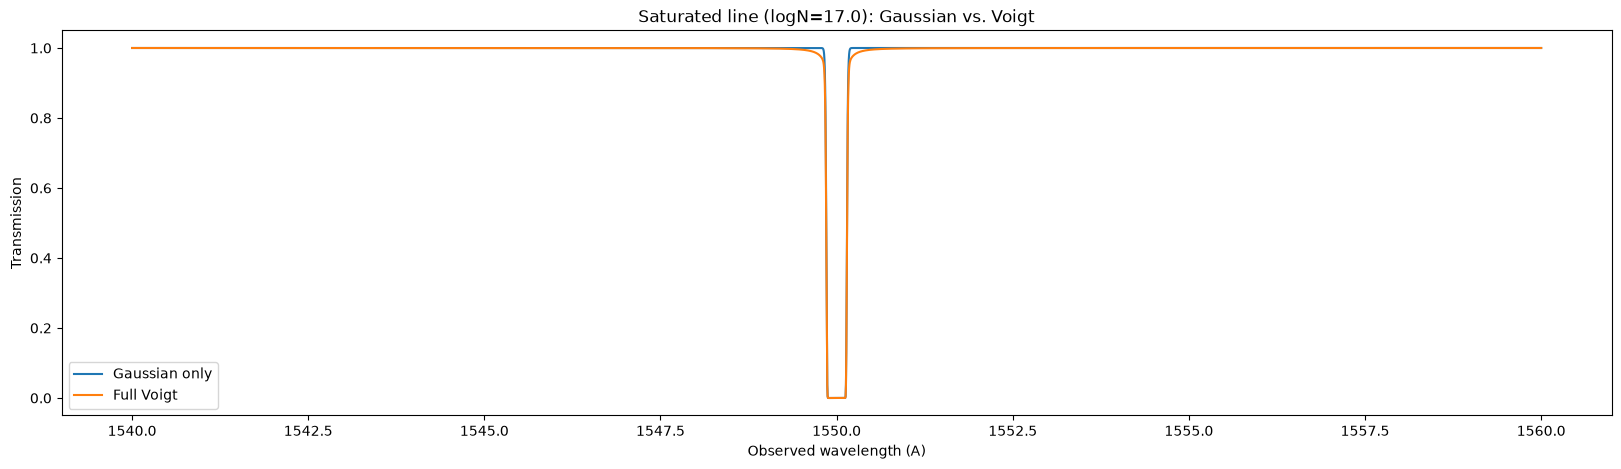

far-wing tau, Gaussian: 0.0
far-wing tau, Voigt   : 4.5703776398396074e-05
PASS: Voigt profile retains real absorption in the wings where Gaussian has vanished.


In [5]:
fig = plt.figure(figsize=(20,5))

logN_sat = 17.0
tau_g_sat = optical_depth_gaussian(wave, line, logN=logN_sat, b=10, z=z)
tau_v_sat = optical_depth(wave, line, logN=logN_sat, b=10, z=z)

plt.plot(wave, np.exp(-tau_g_sat), label="Gaussian only")
plt.plot(wave, np.exp(-tau_v_sat), label="Full Voigt")
plt.xlabel("Observed wavelength (A)")
plt.ylabel("Transmission")
plt.title(f"Saturated line (logN={logN_sat}): Gaussian vs. Voigt")
plt.legend()
plt.show()
plt.close(fig)

far = np.abs(wave - 1550) > 5.0
print("far-wing tau, Gaussian:", tau_g_sat[far].max())
print("far-wing tau, Voigt   :", tau_v_sat[far].max())
assert tau_v_sat[far].max() > 100 * tau_g_sat[far].max(), \
    "Voigt wings should be much larger than the Gaussian-only wings for a saturated line"
print("PASS: Voigt profile retains real absorption in the wings where Gaussian has vanished.")

## Next step

Use `optical_depth` inside the synthetic spectrum generator
(`synthetic_spectrum.make_synthetic`, see `03_synthetic_spectrum.ipynb`) and in the
curve-of-growth validation (damped regime, W ~ sqrt(N)).